# Stake, payout, and expected house win

The previous notebook compared groups of accounts. Here the unit is one player-hand. I want to know how spread out stakes are, and whether the relationship between stake and expected house win looks similar across games.

In [1]:
%matplotlib inline
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect("../private/wagers.duckdb", read_only=True,
                     config={"threads": 4, "memory_limit": "3GB",
                             "temp_directory": "../private/eda-spill"})

In [2]:
moments = con.sql('''
    SELECT game, count(*) AS hands,
           avg(bet) AS mean_stake, var_pop(bet) AS stake_variance,
           stddev_pop(bet) AS stake_sd,
           approx_quantile(bet, 0.5) AS median_stake,
           approx_quantile(bet, 0.95) AS p95_stake,
           avg(wl) AS mean_house_win,
           stddev_pop(wl) AS house_win_sd
    FROM wagers GROUP BY game ORDER BY hands DESC
''').df()
moments.round(2)

,game,hands,mean_stake,stake_variance,stake_sd,median_stake,p95_stake,mean_house_win,house_win_sd
0,non_com,19239765,266.47,1414097.48,1189.16,56.13,972.85,3.45,1139.89
1,super_98,8363099,270.99,1274889.79,1129.11,57.72,984.49,4.67,1089.67
2,lucky_sq,5904458,218.40,1003647.11,1001.82,41.03,811.37,3.59,962.80
3,dragon_tiger,3344853,204.64,2916191.63,1707.69,28.82,551.82,8.64,1441.12
4,roulette,2490500,206.54,826299.67,909.01,50.06,757.86,4.69,965.59
5,fab4,2486314,252.67,1411217.37,1187.95,56.65,935.34,4.14,1153.32
6,traditional,2129100,359.74,4542079.13,2131.22,43.04,1151.20,2.09,1986.54
7,super_sic_bo,1937369,165.21,778845.96,882.52,28.88,556.78,5.84,770.44
8,super_roulette,1280871,124.27,227972.03,477.46,28.57,445.60,5.26,627.72
9,sic_bo,999653,133.07,577560.95,759.97,29.69,437.02,4.88,677.25


The mean is the total amount per player-hand divided by the number of player-hands. Variance measures squared deviations from that mean. Its units are squared stake units, so standard deviation is easier to compare with the stake itself. The median and approximate 95th percentile show what a typical and a high stake look like even when a few large wagers pull the mean upward.

,game,hands,actual_rate,expected_rate,side_bet_share,stake range
0,dragon_tiger,2575102,3.80,4.07,2.52,<100
1,dragon_tiger,679877,4.21,4.01,2.52,100–999
2,dragon_tiger,81800,4.39,3.88,1.60,"1k–9,999"
3,dragon_tiger,8074,4.17,4.40,15.19,10k+
4,non_com,12848630,1.79,1.78,3.50,<100
5,non_com,5510895,1.66,1.61,2.14,100–999
6,non_com,833619,1.27,1.53,1.39,"1k–9,999"
7,non_com,46621,0.29,1.57,1.78,10k+
8,traditional,1430311,1.53,1.58,3.44,<100
9,traditional,577025,1.55,1.56,3.48,100–999


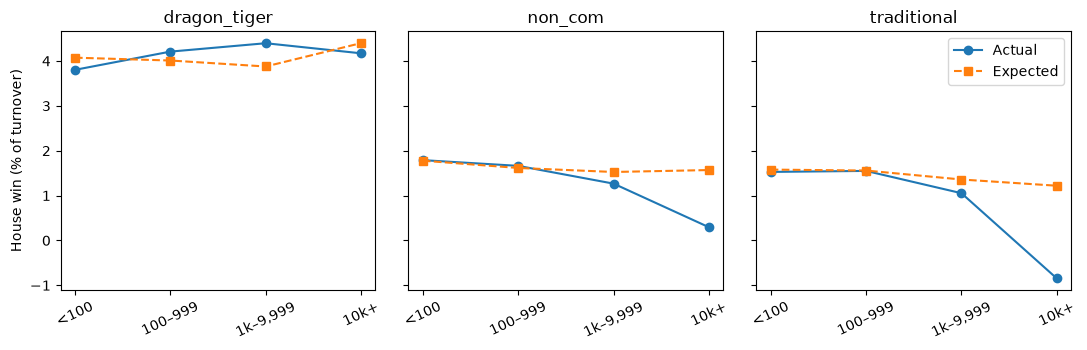

In [3]:
relationships = con.sql('''
    WITH bands AS (
        SELECT game, bet, wl, theo, prop_bet,
               CASE WHEN bet < 100 THEN 1 WHEN bet < 1000 THEN 2
                    WHEN bet < 10000 THEN 3 ELSE 4 END AS stake_band
        FROM wagers WHERE bet > 0
          AND game IN ('traditional', 'non_com', 'dragon_tiger')
    )
    SELECT game, stake_band, count(*) AS hands,
           100 * sum(wl) / sum(bet) AS actual_rate,
           100 * sum(theo) / sum(bet) AS expected_rate,
           100 * sum(prop_bet) / sum(bet) AS side_bet_share
    FROM bands GROUP BY game, stake_band ORDER BY game, stake_band
''').df()
relationships["stake range"] = relationships["stake_band"].map(
    {1: "<100", 2: "100–999", 3: "1k–9,999", 4: "10k+"})
display(relationships.drop(columns="stake_band").round(2))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (game, group) in zip(axes, relationships.groupby("game")):
    ax.plot(group["stake range"], group["actual_rate"], "o-", label="Actual")
    ax.plot(group["stake range"], group["expected_rate"], "s--", label="Expected")
    ax.set_title(game)
    ax.tick_params(axis="x", labelrotation=25)
axes[0].set_ylabel("House win (% of turnover)")
axes[-1].legend()
fig.tight_layout()
plt.show()
con.close()

Expected win already incorporates stake and the edge assigned to each bet. A raw correlation between stake and expected win would largely reflect that calculation. Comparing rates within a game makes differences in bet mix easier to see. Side-bet share is included as context. These group summaries do not isolate its effect or explain why any account bet a particular amount.

In traditional baccarat, the mean stake is about 360, while the median is only 43. The mean alone would give a misleading picture of a typical wager. In the 10,000+ band, the house lost 0.85% of turnover even though the expected house win was 1.22%. That band contains 11,391 player-hands. This is an observed difference within the sample and does not establish that those accounts had an advantage.